In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Day 12 libraries imported successfully.")

Day 12 libraries imported successfully.


In [97]:
day12_input_path = Path(
    "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"
)

if not day12_input_path.exists():
    raise FileNotFoundError(
        f"Input dataset not found: "
        f"{day12_input_path.resolve()}"
    )

df_day12_source = pd.read_csv(
    day12_input_path,
    encoding="cp1252",
    low_memory=False
)

df_day12 = df_day12_source.copy()

print("Day 12 source dataset loaded successfully.")
print("Dataset shape:", df_day12.shape)

display(df_day12.head())

Day 12 source dataset loaded successfully.
Dataset shape: (180519, 56)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode,Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Revenue_Per_Unit,Profit_Margin,Discount_Level,Region_Market,Shipping_Mode_Rank,Is_Corporate_Customer,Order_Quantity_Category,Operational_Risk_Profile,Delivery_Status,Risk_Status
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,78521.0,3,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class,2,1,0,0,Major Delay,0.666667,99.99,0.319412,Low Discount,Pacific Asia - South Asia,4,0,Large,High Risk - Slower Shipping,Delayed,High Risk
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class,0,0,1,0,On Time / Early,1.000000,39.99,0.243611,Medium Discount,LATAM - Central America,4,0,Large,Lower Risk,On Time,Low Risk
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class,0,0,1,0,On Time / Early,1.000000,199.99,0.436822,Low Discount,LATAM - Central America,4,0,Small,Lower Risk,On Time,Low Risk
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class,2,1,0,0,Major Delay,0.666667,199.99,-0.209460,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class,2,1,0,0,Major Delay,0.666667,50.00,0.200000,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk


## Dataset Overview & Validation

In [98]:
required_columns = [
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Delivery Status",
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Order Item Quantity",
    "Shipping Mode",
    "Market",
    "Order Country",
    "Customer Segment",
    "Order Customer Id"
]

missing_columns = [
    col for col in required_columns
    if col not in df_day12.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required financial analysis columns are available.")

print("Total rows:", len(df_day12))
print("Total columns:", len(df_day12.columns))
print("Duplicate rows:", df_day12.duplicated().sum())

display(
    df_day12[required_columns]
    .isna()
    .sum()
    .to_frame(name="Missing_Values")
    .sort_values("Missing_Values", ascending=False)
)

All required financial analysis columns are available.
Total rows: 180519
Total columns: 56
Duplicate rows: 0


,Missing_Values
Is_Delayed,0
Shipping_Delay_Days,0
Delivery Status,0
Sales,0
Order Profit Per Order,0
Order Item Total,0
Order Item Quantity,0
Shipping Mode,0
Market,0
Order Country,0


## Prepare Financial Analysis Columns

In [99]:
financial_columns = [
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Order Item Quantity",
    "Shipping_Delay_Days"
]

for col in financial_columns:
    df_day12[col] = pd.to_numeric(
        df_day12[col],
        errors="coerce"
    )

print("Financial columns converted to numeric format.")

display(
    df_day12[financial_columns]
    .describe()
    .round(2)
)

Financial columns converted to numeric format.


,Sales,Order Profit Per Order,Order Item Total,Order Item Quantity,Shipping_Delay_Days
count,180519.00,180519.00,180519.00,180519.00,180519.00
mean,203.77,21.97,183.11,2.13,0.57
std,132.27,104.43,120.04,1.45,1.49
min,9.99,-4274.98,7.49,1.00,-2.00
25%,119.98,7.00,104.38,1.00,0.00
50%,199.92,31.52,163.99,1.00,1.00
75%,299.95,64.80,247.40,3.00,1.00
max,1999.99,911.80,1939.99,5.00,4.00


### Create the delay category 

In [100]:
print(
    df_day12["Is_Delayed"]
    .value_counts(dropna=False)
    .sort_index()
)

invalid_delay_values = (
    ~df_day12["Is_Delayed"].isin([0, 1])
    & df_day12["Is_Delayed"].notna()
)

print(
    "Invalid delay indicator records:",
    invalid_delay_values.sum()
)

Is_Delayed
0     77119
1    103400
Name: count, dtype: int64
Invalid delay indicator records: 0


In [101]:
df_day12["Delay_Category"] = (
    df_day12["Is_Delayed"]
    .map({
        0: "On Time / Not Delayed",
        1: "Delayed"
    })
)

display(
    df_day12[
        ["Is_Delayed", "Delay_Category"]
    ].head()
)

,Is_Delayed,Delay_Category
0,1,Delayed
1,0,On Time / Not Delayed
2,0,On Time / Not Delayed
3,1,Delayed
4,1,Delayed


## Delay Financial Analysis

In [102]:
delay_financial_analysis = (
    df_day12
    .dropna(subset=["Delay_Category"])
    .groupby("Delay_Category", dropna=False)
    .agg(
        Total_Shipments=(
            "Delay_Category",
            "size"
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Average_Sales_Per_Record=(
            "Sales",
            "mean"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        ),

        Total_Order_Item_Value=(
            "Order Item Total",
            "sum"
        ),

        Average_Order_Item_Value=(
            "Order Item Total",
            "mean"
        ),

        Negative_Profit_Records=(
            "Order Profit Per Order",
            lambda s: s.lt(0).sum()
        )
    )
    .reset_index()
)

total_sales = df_day12["Sales"].sum()

delay_financial_analysis["Sales_Share_%"] = (
    delay_financial_analysis["Total_Sales"]
    / total_sales * 100
    if total_sales != 0
    else np.nan
)

financial_numeric_columns = [
    "Total_Sales",
    "Average_Sales_Per_Record",
    "Total_Order_Profit",
    "Average_Order_Profit",
    "Total_Order_Item_Value",
    "Average_Order_Item_Value",
    "Sales_Share_%"
]

delay_financial_analysis[
    financial_numeric_columns
] = (
    delay_financial_analysis[
        financial_numeric_columns
    ].round(2)
)

display(delay_financial_analysis)

,Delay_Category,Total_Shipments,Total_Sales,Average_Sales_Per_Record,Total_Order_Profit,Average_Order_Profit,Total_Order_Item_Value,Average_Order_Item_Value,Negative_Profit_Records,Sales_Share_%
0,Delayed,103400,21025184.76,203.34,2231966.65,21.59,18889761.93,182.69,19421,57.16
1,On Time / Not Delayed,77119,15759549.55,204.35,1734936.32,22.50,14164640.11,183.67,14363,42.84


## Market-Level Financial Impact 

In [103]:
market_financial_impact = (
    df_day12
    .groupby("Market", dropna=False)
    .agg(
        Total_Shipments=(
            "Market",
            "size"
        ),

        Delayed_Shipments=(
            "Is_Delayed",
            lambda s: s.eq(1).sum()
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        ),

        Negative_Profit_Records=(
            "Order Profit Per Order",
            lambda s: s.lt(0).sum()
        )
    )
    .reset_index()
)

market_delayed = (
    df_day12[df_day12["Is_Delayed"].eq(1)]
    .groupby("Market", dropna=False)
    .agg(
        Delayed_Shipment_Sales=(
            "Sales",
            "sum"
        ),

        Delayed_Shipment_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        )
    )
    .reset_index()
)

market_financial_impact = (
    market_financial_impact
    .merge(
        market_delayed,
        on="Market",
        how="left",
        validate="one_to_one"
    )
)

market_financial_impact[
    "Actual_Delay_Rate_%"
] = (
    market_financial_impact["Delayed_Shipments"]
    / market_financial_impact["Total_Shipments"]
    * 100
)

market_financial_impact[
    "Delayed_Shipment_Share_%"
] = (
    market_financial_impact["Delayed_Shipments"]
    / market_financial_impact["Total_Shipments"]
    * 100
)

market_financial_impact[
    "Sales_Share_From_Delayed_%"
] = (
    market_financial_impact["Delayed_Shipment_Sales"]
    / market_financial_impact["Total_Sales"]
    * 100
)

market_financial_impact = (
    market_financial_impact
    .sort_values(
        "Delayed_Shipment_Sales",
        ascending=False
    )
    .reset_index(drop=True)
)

market_financial_impact = (
    market_financial_impact
    .round(2)
)

display(market_financial_impact)

,Market,Total_Shipments,Delayed_Shipments,Total_Sales,Total_Order_Profit,Average_Order_Profit,Negative_Profit_Records,Delayed_Shipment_Sales,Delayed_Shipment_Order_Profit,Actual_Delay_Rate_%,Delayed_Shipment_Share_%,Sales_Share_From_Delayed_%
0,Europe,50252,28989,10872396.60,1169442.96,23.27,9420,6250879.03,655787.51,57.69,57.69,57.49
1,LATAM,51594,29420,10277612.64,1123321.61,21.77,9588,5862475.78,629766.06,57.02,57.02,57.04
2,Pacific Asia,41260,23649,8273743.58,857753.44,20.79,7806,4736757.26,493560.04,57.32,57.32,57.25
3,USCA,25799,14744,5066528.61,564313.78,21.87,4812,2877201.40,311792.52,57.15,57.15,56.79
4,Africa,11614,6598,2294452.88,252071.18,21.70,2158,1297871.29,141060.52,56.81,56.81,56.57


## Country-Level Financial Impact

In [104]:
country_financial_impact = (
    df_day12
    .groupby("Order Country", dropna=False)
    .agg(
        Total_Shipments=(
            "Order Country",
            "size"
        ),

        Delayed_Shipments=(
            "Is_Delayed",
            lambda s: s.eq(1).sum()
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        ),

        Negative_Profit_Records=(
            "Order Profit Per Order",
            lambda s: s.lt(0).sum()
        )
    )
    .reset_index()
)

country_delayed = (
    df_day12[df_day12["Is_Delayed"].eq(1)]
    .groupby("Order Country", dropna=False)
    .agg(
        Delayed_Shipment_Sales=(
            "Sales",
            "sum"
        ),

        Delayed_Shipment_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        )
    )
    .reset_index()
)

country_financial_impact = (
    country_financial_impact
    .merge(
        country_delayed,
        on="Order Country",
        how="left",
        validate="one_to_one"
    )
)

country_financial_impact[
    "Actual_Delay_Rate_%"
] = (
    country_financial_impact["Delayed_Shipments"]
    / country_financial_impact["Total_Shipments"]
    * 100
)

country_financial_impact[
    "Delayed_Shipment_Share_%"
] = (
    country_financial_impact["Delayed_Shipments"]
    / country_financial_impact["Total_Shipments"]
    * 100
)

country_financial_impact = (
    country_financial_impact
    .sort_values(
        "Delayed_Shipment_Sales",
        ascending=False
    )
    .reset_index(drop=True)
)

country_financial_impact = (
    country_financial_impact
    .round(2)
)

display(country_financial_impact.head(20))

,Order Country,Total_Shipments,Delayed_Shipments,Total_Sales,Total_Order_Profit,Average_Order_Profit,Negative_Profit_Records,Delayed_Shipment_Sales,Delayed_Shipment_Order_Profit,Actual_Delay_Rate_%,Delayed_Shipment_Share_%
0,Estados Unidos,24840,14246,4879667.57,540413.07,21.76,4649,2780606.12,300060.63,57.35,57.35
1,Francia,13222,7663,2879942.31,327828.58,24.79,2391,1678525.93,193244.03,57.96,57.96
2,México,13172,7596,2633195.24,303278.37,23.02,2341,1517571.30,165697.95,57.67,57.67
3,Alemania,9564,5641,2074171.78,194827.08,20.37,1928,1216007.47,116331.87,58.98,58.98
4,Australia,8497,4793,1694621.64,170041.58,20.01,1613,948064.39,95563.66,56.41,56.41
5,Brasil,7987,4566,1594319.92,186713.64,23.38,1465,914086.40,102791.19,57.17,57.17
6,Reino Unido,7302,4092,1612094.82,180942.88,24.78,1347,904720.37,97054.63,56.04,56.04
7,China,5758,3276,1172902.09,122190.92,21.22,1071,665352.49,73541.63,56.89,56.89
8,Italia,4989,2803,1072181.65,121545.47,24.36,912,604268.60,61793.68,56.18,56.18
9,India,4783,2807,962396.68,99746.82,20.85,921,561160.90,61358.79,58.69,58.69


## Shipping Mode Financial Impact

In [105]:
shipping_mode_financial_impact = (
    df_day12
    .groupby("Shipping Mode", dropna=False)
    .agg(
        Total_Shipments=(
            "Shipping Mode",
            "size"
        ),

        Delayed_Shipments=(
            "Is_Delayed",
            lambda s: s.eq(1).sum()
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        ),

        Average_Shipping_Delay_Days=(
            "Shipping_Delay_Days",
            "mean"
        ),

        Negative_Profit_Records=(
            "Order Profit Per Order",
            lambda s: s.lt(0).sum()
        )
    )
    .reset_index()
)

mode_delayed = (
    df_day12[df_day12["Is_Delayed"].eq(1)]
    .groupby("Shipping Mode", dropna=False)
    .agg(
        Delayed_Shipment_Sales=(
            "Sales",
            "sum"
        ),

        Delayed_Shipment_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        )
    )
    .reset_index()
)

shipping_mode_financial_impact = (
    shipping_mode_financial_impact
    .merge(
        mode_delayed,
        on="Shipping Mode",
        how="left",
        validate="one_to_one"
    )
)

shipping_mode_financial_impact[
    "Actual_Delay_Rate_%"
] = (
    shipping_mode_financial_impact["Delayed_Shipments"]
    / shipping_mode_financial_impact["Total_Shipments"]
    * 100
)

shipping_mode_financial_impact = (
    shipping_mode_financial_impact
    .sort_values(
        "Delayed_Shipment_Sales",
        ascending=False
    )
    .reset_index(drop=True)
    .round(2)
)

display(shipping_mode_financial_impact)

,Shipping Mode,Total_Shipments,Delayed_Shipments,Total_Sales,Total_Order_Profit,Average_Order_Profit,Average_Shipping_Delay_Days,Negative_Profit_Records,Delayed_Shipment_Sales,Delayed_Shipment_Order_Profit,Actual_Delay_Rate_%
0,Standard Class,107752,42851,22022391.46,2370454.45,22.00,-0.00,20318,8736397.92,913640.21,39.77
1,Second Class,35216,28078,7145444.68,750308.17,21.31,1.99,6529,5698215.76,588984.98,79.73
2,First Class,27814,27814,5674369.65,643121.92,23.12,1.00,5102,5674369.65,643121.92,100.00
3,Same Day,9737,4657,1942528.52,203018.43,20.85,0.48,1835,916201.43,86219.54,47.83


## Delay Duration & Financial Performance 

In [106]:
display(
    df_day12["Shipping_Delay_Days"]
    .describe()
    .to_frame(name="Shipping_Delay_Days")
)

,Shipping_Delay_Days
count,180519.000000
mean,0.565807
std,1.490966
min,-2.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,4.000000


In [107]:
df_day12["Delay_Duration_Category"] = pd.cut(
    df_day12["Shipping_Delay_Days"],
    bins=[-np.inf, 0, 2, 5, np.inf],
    labels=[
        "On Time / Early",
        "1-2 Days",
        "3-5 Days",
        "More Than 5 Days"
    ],
    right=True
)

df_day12["Delay_Duration_Category"] = (
    df_day12["Delay_Duration_Category"]
    .astype("object")
)

df_day12.loc[
    df_day12["Shipping_Delay_Days"].isna(),
    "Delay_Duration_Category"
] = "Unknown"

In [108]:
delay_duration_financial_analysis = (
    df_day12
    .groupby(
        "Delay_Duration_Category",
        dropna=False,
        observed=True
    )
    .agg(
        Total_Shipments=(
            "Delay_Duration_Category",
            "size"
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Average_Sales_Per_Record=(
            "Sales",
            "mean"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        ),

        Negative_Profit_Records=(
            "Order Profit Per Order",
            lambda s: s.lt(0).sum()
        )
    )
    .reset_index()
    .round(2)
)

display(delay_duration_financial_analysis)

,Delay_Duration_Category,Total_Shipments,Total_Sales,Average_Sales_Per_Record,Total_Order_Profit,Average_Order_Profit,Negative_Profit_Records
0,1-2 Days,89365,18163026.48,203.25,1940779.93,21.72,16847
1,3-5 Days,14035,2862158.28,203.93,291186.72,20.75,2574
2,On Time / Early,77119,15759549.55,204.35,1734936.32,22.50,14363


## Negative-Profit Analysis

In [109]:
df_day12["Negative_Profit_Flag"] = (
    df_day12["Order Profit Per Order"] < 0
).astype(int)

print(
    "Negative-profit records:",
    df_day12["Negative_Profit_Flag"].sum()
)

print(
    "Negative-profit percentage:",
    round(
        df_day12["Negative_Profit_Flag"].mean() * 100,
        2
    )
)

Negative-profit records: 33784
Negative-profit percentage: 18.71


In [110]:
negative_profit_analysis = (
    df_day12
    .groupby("Delay_Category", dropna=False)
    .agg(
        Total_Shipments=(
            "Delay_Category",
            "size"
        ),

        Negative_Profit_Records=(
            "Negative_Profit_Flag",
            "sum"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        )
    )
    .reset_index()
)

negative_profit_analysis[
    "Negative_Profit_Rate_%"
] = (
    negative_profit_analysis["Negative_Profit_Records"]
    / negative_profit_analysis["Total_Shipments"]
    * 100
)

negative_profit_analysis = (
    negative_profit_analysis
    .round(2)
)

display(negative_profit_analysis)

,Delay_Category,Total_Shipments,Negative_Profit_Records,Total_Order_Profit,Average_Order_Profit,Negative_Profit_Rate_%
0,Delayed,103400,19421,2231966.65,21.59,18.78
1,On Time / Not Delayed,77119,14363,1734936.32,22.50,18.62


## Visual Analysis

### Section 11A: Sales Associated with Delayed and Non-Delayed Shipments

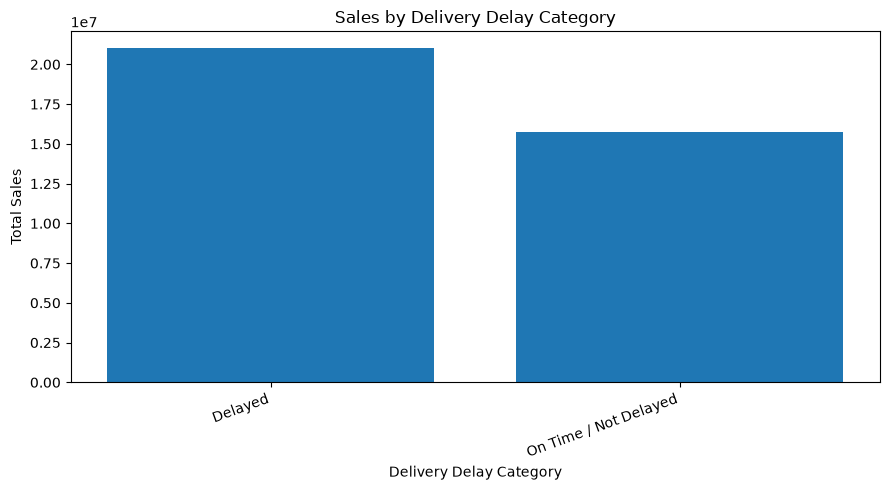

In [111]:
plot_data = delay_financial_analysis.copy()

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["Delay_Category"].astype(str),
    plot_data["Total_Sales"]
)

plt.title("Sales by Delivery Delay Category")
plt.xlabel("Delivery Delay Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Section 11B: Delayed-Shipment Sales by Market

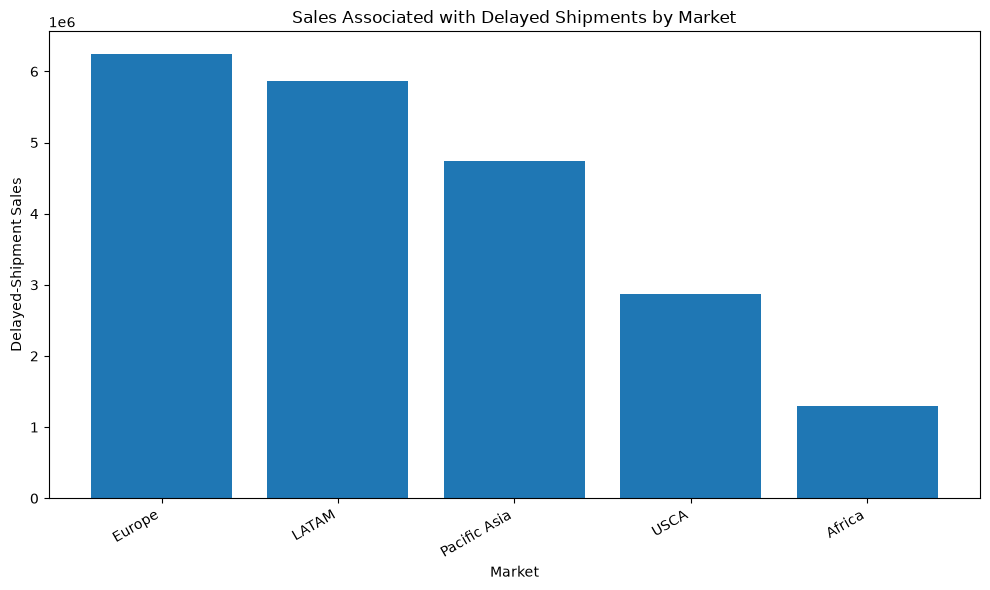

In [112]:
plot_data = (
    market_financial_impact
    .sort_values(
        "Delayed_Shipment_Sales",
        ascending=False
    )
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data["Market"].astype(str),
    plot_data["Delayed_Shipment_Sales"]
)

plt.title("Sales Associated with Delayed Shipments by Market")
plt.xlabel("Market")
plt.ylabel("Delayed-Shipment Sales")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Section 11C: Actual Delay Rate by Shipping Mode

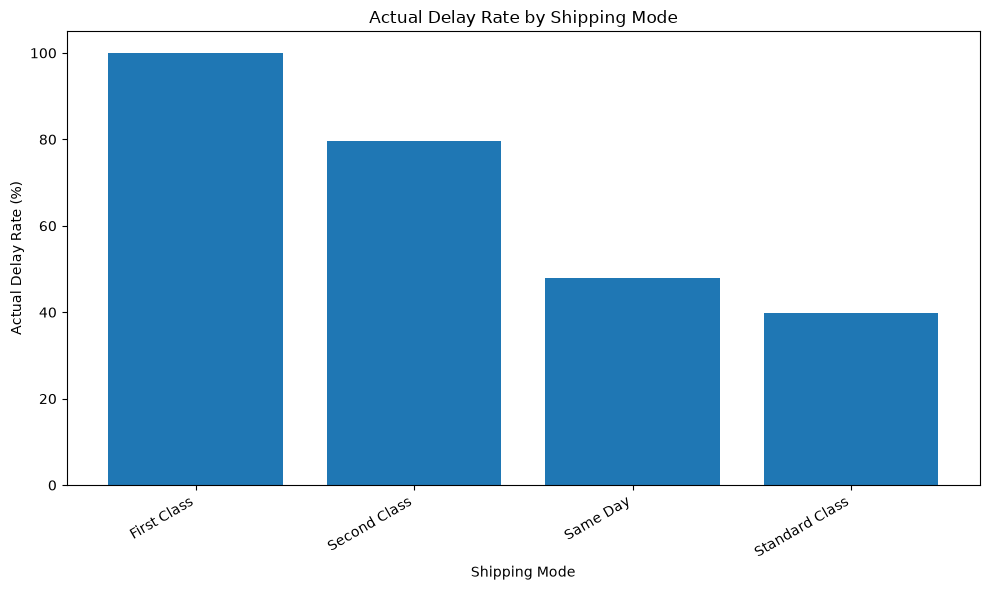

In [113]:
plot_data = (
    shipping_mode_financial_impact
    .sort_values(
        "Actual_Delay_Rate_%",
        ascending=False
    )
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data["Shipping Mode"].astype(str),
    plot_data["Actual_Delay_Rate_%"]
)

plt.title("Actual Delay Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Actual Delay Rate (%)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Section 11D: Average Order Profit by Delay Duration

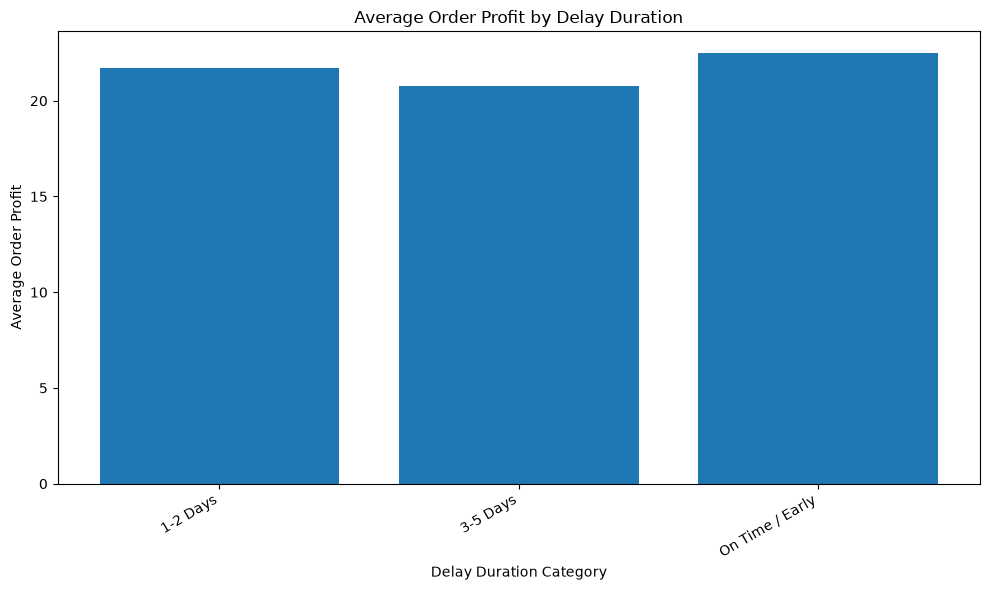

In [114]:
plot_data = delay_duration_financial_analysis.copy()

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data["Delay_Duration_Category"].astype(str),
    plot_data["Average_Order_Profit"]
)

plt.title("Average Order Profit by Delay Duration")
plt.xlabel("Delay Duration Category")
plt.ylabel("Average Order Profit")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Financial Impact KPI Summary

In [115]:
total_shipments = len(df_day12)

delayed_mask = df_day12["Is_Delayed"].eq(1)

delayed_shipments = int(
    delayed_mask.sum()
)

total_sales = df_day12["Sales"].sum()

total_order_profit = (
    df_day12["Order Profit Per Order"].sum()
)

delayed_shipment_sales = (
    df_day12.loc[delayed_mask, "Sales"].sum()
)

delayed_shipment_order_profit = (
    df_day12.loc[
        delayed_mask,
        "Order Profit Per Order"
    ].sum()
)

negative_profit_records = int(
    df_day12["Negative_Profit_Flag"].sum()
)

actual_delay_rate = (
    delayed_shipments / total_shipments * 100
    if total_shipments > 0
    else np.nan
)

negative_profit_rate = (
    negative_profit_records / total_shipments * 100
    if total_shipments > 0
    else np.nan
)

highest_exposure_market = (
    market_financial_impact
    .dropna(subset=["Delayed_Shipment_Sales"])
    .sort_values(
        "Delayed_Shipment_Sales",
        ascending=False
    )
    .iloc[0]["Market"]
    if not market_financial_impact.empty
    and market_financial_impact[
        "Delayed_Shipment_Sales"
    ].notna().any()
    else "Not Available"
)

highest_exposure_country = (
    country_financial_impact
    .dropna(subset=["Delayed_Shipment_Sales"])
    .sort_values(
        "Delayed_Shipment_Sales",
        ascending=False
    )
    .iloc[0]["Order Country"]
    if not country_financial_impact.empty
    and country_financial_impact[
        "Delayed_Shipment_Sales"
    ].notna().any()
    else "Not Available"
)

highest_delay_mode = (
    shipping_mode_financial_impact
    .dropna(subset=["Actual_Delay_Rate_%"])
    .sort_values(
        "Actual_Delay_Rate_%",
        ascending=False
    )
    .iloc[0]["Shipping Mode"]
    if not shipping_mode_financial_impact.empty
    and shipping_mode_financial_impact[
        "Actual_Delay_Rate_%"
    ].notna().any()
    else "Not Available"
)

day12_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipment Records",
        "Total Sales",
        "Total Order Profit",
        "Delayed Shipments",
        "Actual Delay Rate (%)",
        "Sales Associated with Delayed Shipments",
        "Order Profit Associated with Delayed Shipments",
        "Negative-Profit Records",
        "Negative-Profit Rate (%)",
        "Market with Highest Delayed-Shipment Sales",
        "Country with Highest Delayed-Shipment Sales",
        "Shipping Mode with Highest Actual Delay Rate"
    ],

    "Value": [
        total_shipments,
        round(total_sales, 2),
        round(total_order_profit, 2),
        delayed_shipments,
        round(actual_delay_rate, 2),
        round(delayed_shipment_sales, 2),
        round(delayed_shipment_order_profit, 2),
        negative_profit_records,
        round(negative_profit_rate, 2),
        highest_exposure_market,
        highest_exposure_country,
        highest_delay_mode
    ]
})

display(day12_kpis)

,Metric,Value
0,Total Shipment Records,180519
1,Total Sales,36784734.31
2,Total Order Profit,3966902.97
3,Delayed Shipments,103400
4,Actual Delay Rate (%),57.28
5,Sales Associated with Delayed Shipments,21025184.76
6,Order Profit Associated with Delayed Shipments,2231966.65
7,Negative-Profit Records,33784
8,Negative-Profit Rate (%),18.71
9,Market with Highest Delayed-Shipment Sales,Europe


## Saving Day 12 Financial Impact Results

In [116]:
day12_output_dir = Path(
    "../data/analysis_data/"
)

if not day12_output_dir.exists():
    raise FileNotFoundError(
        "Output directory does not exist: "
        f"{day12_output_dir.resolve()}"
    )

day12_outputs = {
    "APL_Day12_Financial_Impact_KPIs.csv":
        day12_kpis,

    "APL_Day12_Delay_Financial_Analysis.csv":
        delay_financial_analysis,

    "APL_Day12_Market_Financial_Impact.csv":
        market_financial_impact,

    "APL_Day12_Country_Financial_Impact.csv":
        country_financial_impact,

    "APL_Day12_Shipping_Mode_Financial_Impact.csv":
        shipping_mode_financial_impact,

    "APL_Day12_Delay_Duration_Financial_Analysis.csv":
        delay_duration_financial_analysis,

    "APL_Day12_Negative_Profit_Analysis.csv":
        negative_profit_analysis
}

for filename, output_df in day12_outputs.items():

    output_path = day12_output_dir / filename

    output_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved:", output_path.resolve())

print("All Day 12 analysis outputs saved successfully.")

Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day12_Financial_Impact_KPIs.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day12_Delay_Financial_Analysis.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day12_Market_Financial_Impact.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day12_Country_Financial_Impact.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day12_Shipping_Mode_Financial_Impact.csv
Saved: D:\Data Analytics Project\

## Validation Report for Day 12

In [117]:
shipment_totals_valid = (
    delay_financial_analysis["Total_Shipments"].sum()
    == df_day12["Delay_Category"].notna().sum()
)

delay_totals_valid = (
    delay_financial_analysis.loc[
        delay_financial_analysis["Delay_Category"]
        == "Delayed",
        "Total_Shipments"
    ].sum()
    == delayed_shipments
)

market_shipments_valid = (
    market_financial_impact["Total_Shipments"].sum()
    == len(df_day12)
)

country_shipments_valid = (
    country_financial_impact["Total_Shipments"].sum()
    == len(df_day12)
)

mode_shipments_valid = (
    shipping_mode_financial_impact[
        "Total_Shipments"
    ].sum()
    == len(df_day12)
)

delayed_sales_valid = np.isclose(
    delay_financial_analysis.loc[
        delay_financial_analysis["Delay_Category"]
        == "Delayed",
        "Total_Sales"
    ].sum(),
    delayed_shipment_sales,
    equal_nan=False
)

output_files_exist = all(
    (day12_output_dir / filename).exists()
    for filename in day12_outputs
)

validation_results = {
    "Source Dataset Loaded":
        not df_day12.empty,

    "Required Columns Available":
        len(missing_columns) == 0,

    "Delay Financial Analysis Not Empty":
        not delay_financial_analysis.empty,

    "Market Financial Analysis Not Empty":
        not market_financial_impact.empty,

    "Country Financial Analysis Not Empty":
        not country_financial_impact.empty,

    "Shipping Mode Analysis Not Empty":
        not shipping_mode_financial_impact.empty,

    "Shipment Totals Reconcile":
        shipment_totals_valid,

    "Delayed Shipment Totals Reconcile":
        delay_totals_valid,

    "Market Shipment Totals Reconcile":
        market_shipments_valid,

    "Country Shipment Totals Reconcile":
        country_shipments_valid,

    "Shipping Mode Shipment Totals Reconcile":
        mode_shipments_valid,

    "Delayed Sales Reconcile":
        delayed_sales_valid,

    "All Analytical Output Files Exist":
        output_files_exist
}

day12_validation = pd.DataFrame([
    {
        "Validation_Check": check,
        "Status": "PASS" if passed else "FAIL"
    }
    for check, passed in validation_results.items()
])

display(day12_validation)

if all(validation_results.values()):
    print("ALL DAY 12 VALIDATION CHECKS PASSED.")
else:
    print("DAY 12 VALIDATION REQUIRES ATTENTION.")

    display(
        day12_validation[
            day12_validation["Status"] == "FAIL"
        ]
    )

,Validation_Check,Status
0,Source Dataset Loaded,PASS
1,Required Columns Available,PASS
2,Delay Financial Analysis Not Empty,PASS
3,Market Financial Analysis Not Empty,PASS
4,Country Financial Analysis Not Empty,PASS
5,Shipping Mode Analysis Not Empty,PASS
6,Shipment Totals Reconcile,PASS
7,Delayed Shipment Totals Reconcile,PASS
8,Market Shipment Totals Reconcile,PASS
9,Country Shipment Totals Reconcile,PASS


ALL DAY 12 VALIDATION CHECKS PASSED.


### Saving the validation report

In [118]:
validation_path = (
    day12_output_dir
    / "APL_Day12_Validation.csv"
)

day12_validation.to_csv(
    validation_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Validation report saved:",
    validation_path.resolve()
)

Validation report saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day12_Validation.csv
